<a href="https://colab.research.google.com/github/maximofernandezriera/taller-pizarra/blob/main/parte-C-pizarra-devin-web-SWE2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte C - la máquina de recorrer (taller de bicis de Marina)

**Devin web SWE-2, revisión técnica y de formato posterior.**

[Abre este cuaderno en Colab](https://colab.research.google.com/github/maximofernandezriera/taller-pizarra/blob/main/parte-C-pizarra-devin-web-SWE2.ipynb)

**Guion de pizarra para la corrección de C1, C2 y C3 - ~50–55 min.**

Los tres ejercicios comparten **recorrer, comprobar y decidir**, pero cambian sus variables y el momento del retorno: una cinta
transportadora que pasa cajas una a una bajo un "preguntador", y tres cubos
posibles: **PARAR** (C1), **CONTAR** (C2), **GUARDAR** (C3). Se explica la
máquina una vez; cada ejercicio solo rellena su fila de la tabla.

| Tramo | Min | Qué |
|---|---|---|
| 0–8 | 8 | La máquina + simulacro humano (sin código) |
| 8–20 | 12 | C1 · primera_revision (early return + -1) |
| 20–30 | 10 | C2 · contar_cortas (carácter a carácter) |
| 30–42 | 12 | C3 · subir_stock (lista nueva + muro) |
| 42–52 | 10 | Tabla resumen colectiva + quiz de casos límite |

**Narrativa:** primero simulación y preguntas, después la receta en español,
y al final el código progresivo comentado - una línea de receta = un renglón.
Sangría de 4 espacios en todo el paquete.

## Cómo usarlo

Las imágenes y animaciones ya se ven en las salidas guardadas. Para recalcular: Entorno de ejecución > Ejecutar todas. La preparación de recursos está plegada para no distraer de la explicación.

Al final puedes descargar las pizarras Excalidraw editables, GIFs, guion TXT y PDF en un ZIP integrado, sin enlaces privados.

## 0 · La máquina (8 min, sin código)

**Simulacro humano:** 5 alumnos de pie, cada uno con una cartulina-número
(3, 8, 12, 6, 10). El profesor es el dedo: apunta a cada uno, pregunta en
voz alta y la clase decide qué hace la máquina. **Nadie escribe Python.**

Dibujar en la pizarra, en este orden:

1. La cinta con 4–5 cajas vacías y la flecha del dedo.
2. El preguntador (rombo/globo): "¿PREGUNTA? → SÍ / NO".
3. Los tres cubos de salida: **PARAR → devolver ya**, **CONTAR +1**,
   **GUARDAR en lista nueva**.
4. La tabla de 3 columnas (queda en la pizarra toda la clase).

In [ ]:
#@title Preparar imágenes y animaciones integradas
# Recursos integrados: no requiere descargar otros archivos del repositorio.
import base64
from pathlib import Path
RAIZ = Path('/tmp/parte_c_pizarra')
RECURSOS = {'figuras/c1_inicial.png': '...', 'figuras/c3_resuelta.png': '...', 'figuras/c3_inicial.png': '...', 'figuras/c2_resuelta.png': '...', 'figuras/c1_resuelta.png': '...', 'figuras/c2_inicial.png': '...', 'figuras/pizarra_maquina.png': '...', 'gifs/c1_primera_revision.gif': '...', 'gifs/c3_subir_stock.gif': '...', 'gifs/c2_contar_cortas.gif': '...'}
for nombre, datos in RECURSOS.items():
    destino = RAIZ / nombre
    destino.parent.mkdir(parents=True, exist_ok=True)
    destino.write_bytes(base64.b64decode(datos))


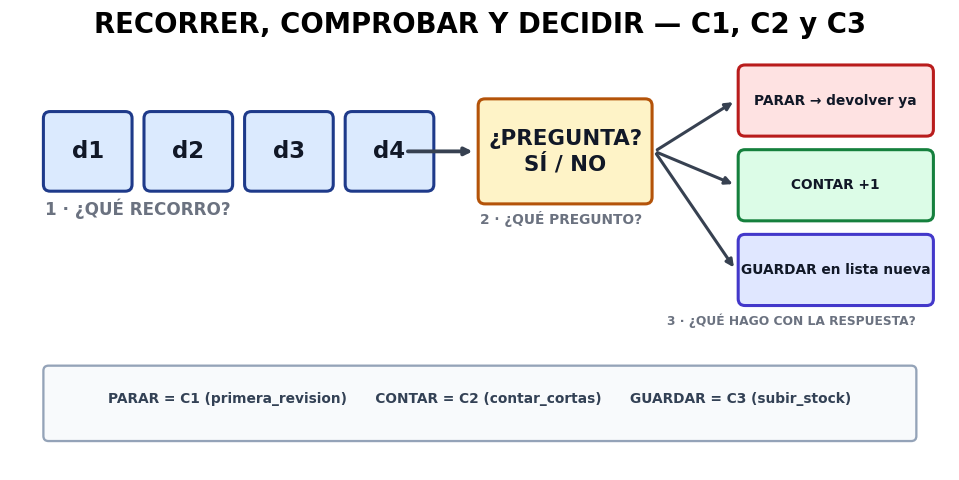

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/pizarra_maquina.png")))

| | ¿Qué recorro? | ¿Qué pregunto a cada uno? | ¿Qué hago con la respuesta? |
|---|---|---|---|
| **C1** | las mediciones (pos = percha) | ¿m > limite? | PARAR y devolver `pos`; si no, -1 |
| **C2** | los caracteres | al espacio: ¿0 < longitud < maximo? | CONTAR +1 (y reiniciar longitud) |
| **C3** | las unidades | ¿u + extra > tope? | GUARDAR el valor (capado) en `nueva` |

La tabla la rellenamos **entre todos al final** de cada ejercicio; es el
esqueleto compartido. Los alumnos descubren que programar es responder tres
preguntas, no memorizar soluciones.

## C1 · primera_revision (~12 min)

**Contrato:** `primera_revision(mediciones, limite)` devuelve la **posición**
(la primera es la 0) de la primera medición **estrictamente mayor** que
`limite`, o **-1** si ninguna la supera.

```python
primera_revision([3, 8, 12, 6, 10], 10)   # -> 2
primera_revision([3, 8], 10)              # -> -1
```

### 1 · Qué dibujar (en orden)

1. Cajas `[3][8][12][6][10]` con **dos etiquetas**: índice debajo (0–4, otro
   color) y valor arriba. En el taller: la **percha** es la posición, la
   **bici** es el valor - dos carteles de la misma caja.
2. Flecha-dedo de izquierda a derecha; sobre cada caja NO, NO, **SÍ**.
   STOP en el 12 → salida `2`.
3. Borrar valores y repetir con `[3, 8]`: el dedo recorre todo y **cae por
   el borde** → `return -1`.

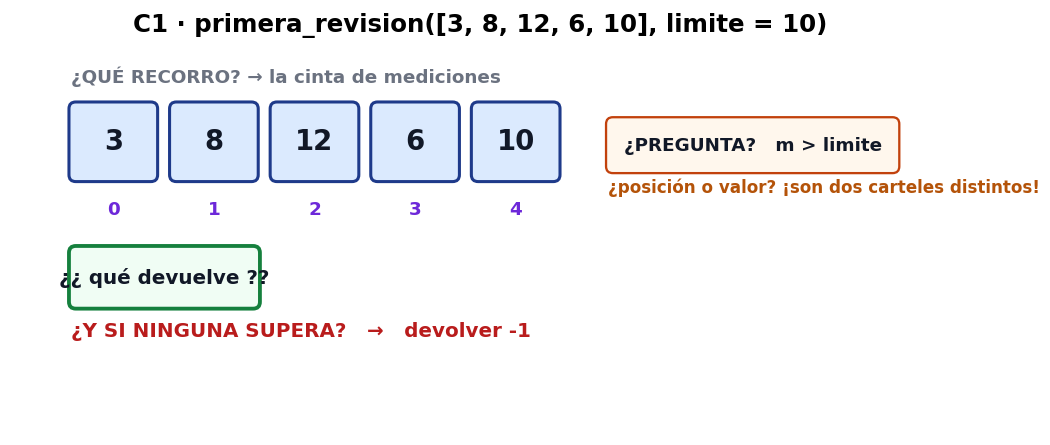

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c1_inicial.png")))

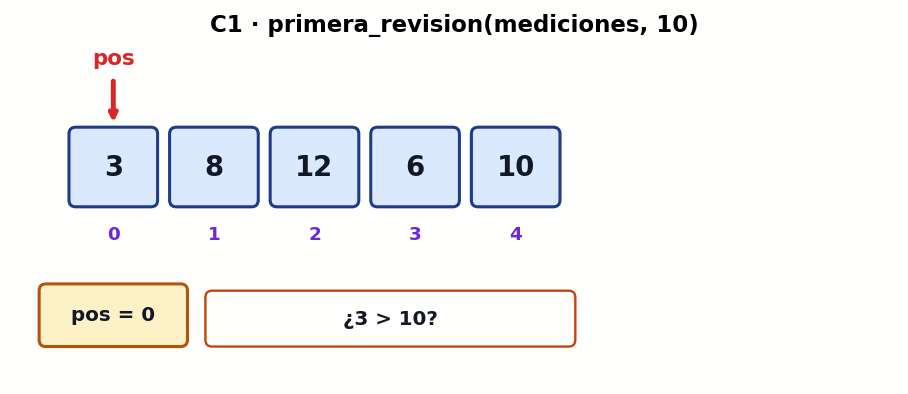

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "gifs/c1_primera_revision.gif"), format="gif"))

### 2 · Preguntas y errores a provocar

| Pregunta | Respuesta esperada |
|---|---|
| ¿Y si la primera ya supera? | Devuelve 0: el dedo ni se mueve |
| ¿Sigo mirando tras el SÍ? | No: `[3,8,12,15,10]` daría 3, no 2 |
| ¿posición o valor? | La percha (`pos`), no la bici (`m`) |

| Error a dibujar | Contraejemplo que lo delata |
|---|---|
| `>=` en vez de `>` | `[10]` con limite 10 → 0, debe ser -1 |
| `return -1` dentro del for | cualquier lista → se rinde en la primera |
| devolver `m` (el valor) | devuelve 12, no 2 |

Los errores se **programan mal primero** y se detectan trazando:

In [ ]:
# ❌ ERROR 1: return -1 dentro del bucle (se rinde en la primera)
def mal_dentro(mediciones, limite):
    pos = 0
    for m in mediciones:
        if m > limite:
            return pos
        else:
            return -1
        pos = pos + 1

print("mal_dentro  ->", mal_dentro([3, 8, 12, 6, 10], 10), " (debe ser 2)")


# ❌ ERROR 2: >= en vez de >
def mal_igual(mediciones, limite):
    pos = 0
    for m in mediciones:
        if m >= limite:
            return pos
        pos = pos + 1
    return -1

print("mal_igual   ->", mal_igual([10], 10), " (debe ser -1: 10 NO es > 10)")


# ❌ ERROR 3: devuelve el VALOR, no la posición
def mal_valor(mediciones, limite):
    for m in mediciones:
        if m > limite:
            return m
    return -1

print("mal_valor   ->", mal_valor([3, 8, 12, 6, 10], 10), " (debe ser 2)")

mal_dentro  -> -1  (debe ser 2)
mal_igual   -> 0  (debe ser -1: 10 NO es > 10)
mal_valor   -> 12  (debe ser 2)


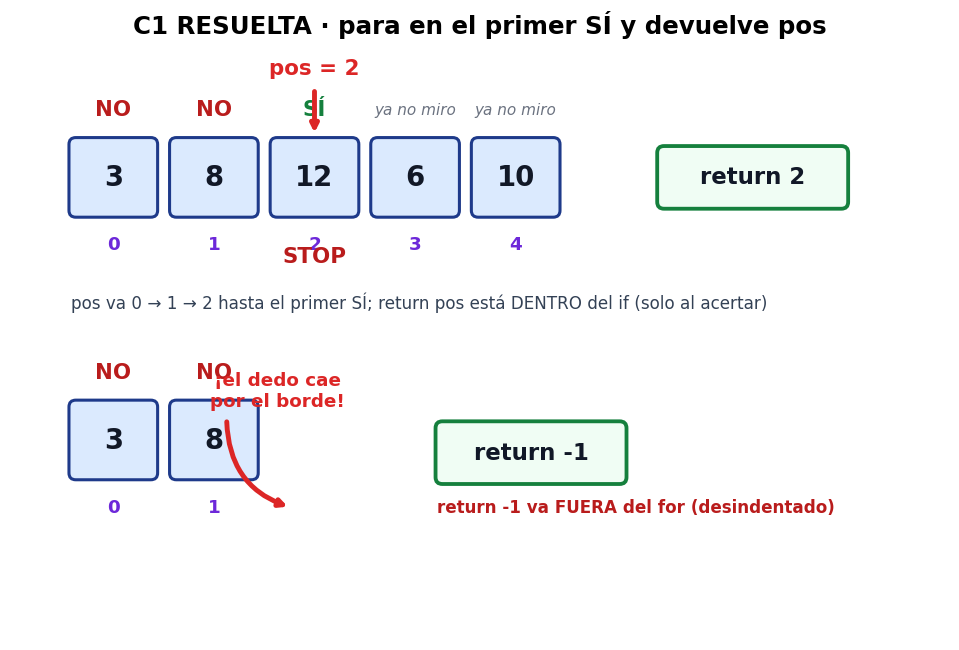

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c1_resuelta.png")))

### 3 · Del dibujo al código

**Momento exacto:** cuando la clase puede **decir la receta** sin ayuda.
Escribirla en español a la izquierda y traducir línea a línea
("¿cómo se dice esto en Python?") - una línea de receta = un renglón:

La receta se traduce en el bloque de código siguiente, con una instrucción por línea y sangría visible.

`return -1` va **desindentado**: es "el dedo cayó".

In [ ]:
# ✅ SOLUCIÓN — cada renglón se lee del dibujo
def primera_revision(mediciones, limite):
    # pos va contando perchas: 0, 1, 2, ...
    pos = 0
    for m in mediciones:
        if m > limite:
            return pos
        pos = pos + 1
    # el dedo cayó por el borde: ninguna supera el límite
    return -1

print(primera_revision([3, 8, 12, 6, 10], 10))   # 2
print(primera_revision([3, 8], 10))              # -1

2
-1


### 4 · Casos límite (ellos predicen antes de revelar)

In [ ]:
# lista vacía · la primera pasa · ninguna pasa · límite estricto · la última
pruebas = [([3, 8, 12, 6, 10], 10, 2), ([3, 8], 10, -1), ([], 10, -1),
           ([11], 10, 0), ([10], 10, -1), ([1, 2, 3, 15], 10, 3),
           ([5, 12, 13], 10, 1)]
for meds, lim, esperado in pruebas:
    obtenido = primera_revision(meds, lim)
    assert obtenido == esperado, (meds, lim, obtenido, esperado)
print("todas las pruebas de C1 OK")

todas las pruebas de C1 OK


**PythonTutor** (código exacto, para visualizar la traza):
[abrir primera_revision en PythonTutor](https://pythontutor.com/render.html#code=def%20primera_revision%28mediciones%2C%20limite%29%3A%0A%20%20%20%20%23%20pos%20va%20contando%20perchas%3A%200%2C%201%2C%202%2C%20...%0A%20%20%20%20pos%20%3D%200%0A%20%20%20%20for%20m%20in%20mediciones%3A%0A%20%20%20%20%20%20%20%20if%20m%20%3E%20limite%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20return%20pos%0A%20%20%20%20%20%20%20%20pos%20%3D%20pos%20%2B%201%0A%20%20%20%20%23%20el%20dedo%20cay%C3%B3%20por%20el%20borde%3A%20ninguna%20supera%20el%20l%C3%ADmite%0A%20%20%20%20return%20-1%0A%0Aprint%28primera_revision%28%5B3%2C%208%2C%2012%2C%206%2C%2010%5D%2C%2010%29%29&cumulative=false&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=3&rawInputLstJSON=%5B%5D&textReferences=false)

### Mini-reto C1 (5 min, para casa o pizarra)

`ultima_revision(mediciones, limite)` → posición de la **última** medición
estrictamente mayor que `limite`, o -1. Pista: ya **no se para**; hay que
**recordar** la última posición buena.

**Solución del reto C1** *(solo profesor)* - misma máquina, el cubo
PARAR se cambia por "guardar y seguir":

In [ ]:
def ultima_revision(mediciones, limite):
    res = -1          # de momento, ninguna
    pos = 0
    for m in mediciones:
        if m > limite:
            res = pos      # recuerdo la última buena, no paro
        pos = pos + 1
    return res

assert ultima_revision([3, 8, 12, 15, 10], 10) == 3
assert ultima_revision([3, 8], 10) == -1
assert ultima_revision([12, 4, 13], 10) == 2
print("reto C1 OK")

reto C1 OK


## C2 · contar_cortas (~10 min)

**Contrato:** `contar_cortas(texto, maximo)` devuelve cuántas palabras de
`texto` tienen longitud **estrictamente menor** que `maximo`. El texto puede
llevar **espacios extra al principio y al final** (¡y repetidos!).

```python
contar_cortas("rueda pinchada hoy", 7)   # -> 2   (rueda=5, hoy=3)
contar_cortas("", 5)                     # -> 0
```

Mismo patrón general, pero cambian el recorrido, el estado y cuándo se decide. ¿Qué recorremos?
**Carácter a carácter** (sin `split` como solución principal: obliga a
entender qué es una palabra).

### 1 · Qué dibujar (en orden)

1. Cinta de **caracteres** de `"  rueda pinchada hoy  "` - los espacios
   como celdas `␣`, incluidos los de los extremos.
2. Dos cajas-contador: `longitud = 0` (amarilla) y `contador = 0` (verde).
3. La pregunta solo se dispara **al leer un espacio**: ¿0 < longitud < max?
   Si sí → +1; luego `longitud` vuelve a 0.
4. Compara con `"rueda pinchada hoy"`, sin espacio final: `hoy` solo se cuenta al salir del bucle. Si el texto sí termina en espacio, longitud ya vale 0 y la comprobación final no suma otra vez.

En el recorrido principal, el separador es el espacio ordinario (`" "`). La comparación con `split()` coincide en los ejemplos del examen; `split()` además separa tabulaciones y saltos de línea.

El recorrido principal separa por espacio ordinario. `split()` también separa tabulaciones y saltos de línea; aquí se comparan textos con espacios.

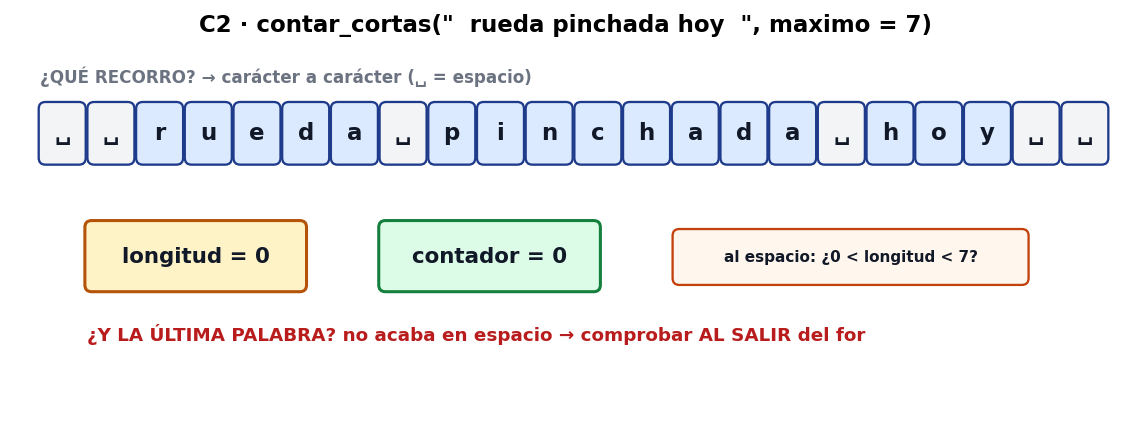

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c2_inicial.png")))

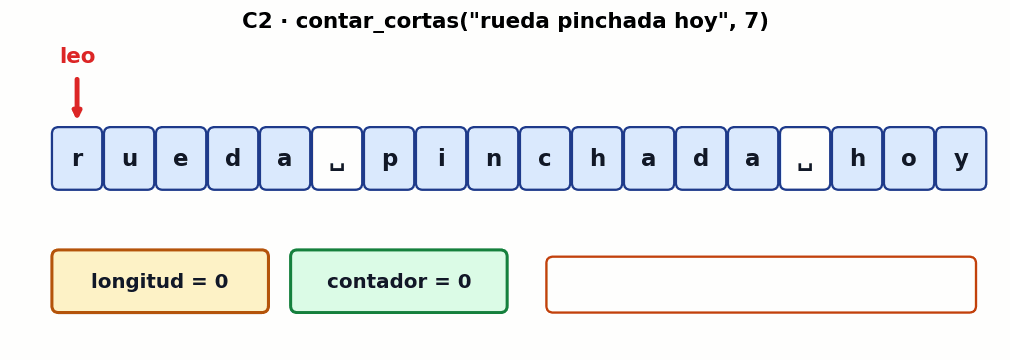

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "gifs/c2_contar_cortas.gif"), format="gif"))

### 2 · Preguntas y errores a provocar

| Pregunta | Respuesta esperada |
|---|---|
| ¿Y si son solo espacios / vacío? | Cinta vacía o longitud 0 → 0 |
| ¿Dos espacios seguidos? | El segundo ve longitud = 0 → no cuenta |
| ¿Palabra de exactamente `maximo`? | No cuenta: es `<` estricto |

| Error a dibujar | Contraejemplo que lo delata |
|---|---|
| `<=` en vez de `<` | `"sieteaa"` con max 7 → 1, debe ser 0 |
| olvidar el if final | `"…hoy"` sin espacio final → pierde la última |
| `return` dentro del for | devuelve tras el primer espacio |

In [ ]:
# ❌ ERROR 1: <= en vez de < (cuenta palabras de exactamente maximo)
def mal_igual(texto, maximo):
    contador = 0
    longitud = 0
    for c in texto:
        if c == " ":
            if 0 < longitud <= maximo:
                contador = contador + 1
            longitud = 0
        else:
            longitud = longitud + 1
    if 0 < longitud <= maximo:
        contador = contador + 1
    return contador

print("mal_igual     ->", mal_igual("sieteaa", 7), " (debe ser 0)")


# ❌ ERROR 2: falta el if FINAL (la última palabra se pierde)
def mal_sin_final(texto, maximo):
    contador = 0
    longitud = 0
    for c in texto:
        if c == " ":
            if 0 < longitud < maximo:
                contador = contador + 1
            longitud = 0
        else:
            longitud = longitud + 1
    return contador

print("mal_sin_final ->", mal_sin_final("rueda pinchada hoy", 7),
      " (debe ser 2)")

mal_igual     -> 1  (debe ser 0)
mal_sin_final -> 1  (debe ser 2)


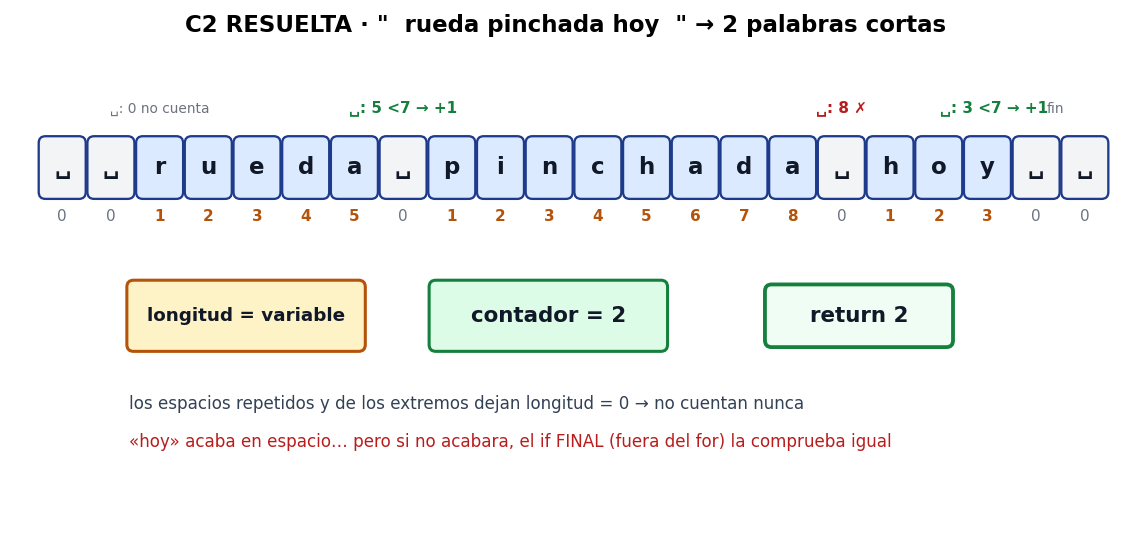

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c2_resuelta.png")))

### 3 · Del dibujo al código

Rellenamos la fila C2 de la tabla antes de escribir: cambian el dato recorrido, el estado y el momento de decidir: aquí contamos al cerrar cada palabra.

La receta se traduce en el bloque de código siguiente, con una instrucción por línea y sangría visible.

In [ ]:
# ✅ SOLUCIÓN — sin split(): así se ve de verdad qué es una palabra
def contar_cortas(texto, maximo):
    # recorremos carácter a carácter, sin split()
    contador = 0
    longitud = 0
    for c in texto:
        if c == " ":
            if 0 < longitud < maximo:
                contador = contador + 1
            longitud = 0
        else:
            longitud = longitud + 1
    # la última palabra no acaba en espacio: se comprueba al salir
    if 0 < longitud < maximo:
        contador = contador + 1
    return contador

print(contar_cortas("rueda pinchada hoy", 7))   # 2
print(contar_cortas("", 5))                     # 0

2
0


**Comparación final válida para el examen:** la versión corta con
`split()` - los espacios extra se los come sola - da el mismo resultado:

In [ ]:
def contar_cortas_corta(texto, maximo):
    contador = 0
    for palabra in texto.split():
        if len(palabra) < maximo:
            contador = contador + 1
    return contador

print(contar_cortas_corta("rueda pinchada hoy", 7))    # 2
print(contar_cortas_corta("  a  bb   ccc ", 4))        # 3: split() se come
                                                     # los espacios extra

2
3


### 4 · Casos límite

In [ ]:
pruebas = [("rueda pinchada hoy", 7, 2), ("", 5, 0), ("   ", 5, 0),
           ("  hola  ", 5, 1), ("a  bb   ccc", 4, 3), ("sieteaa", 7, 0),
           ("hoy", 5, 1), ("una dos tres", 4, 2)]
for texto, mx, esperado in pruebas:
    obtenido = contar_cortas(texto, mx)
    assert obtenido == esperado, (texto, mx, obtenido, esperado)
    assert contar_cortas_corta(texto, mx) == esperado
print("todas las pruebas de C2 OK")

todas las pruebas de C2 OK


**PythonTutor:**
[abrir contar_cortas en PythonTutor](https://pythontutor.com/render.html#code=def%20contar_cortas%28texto%2C%20maximo%29%3A%0A%20%20%20%20%23%20recorremos%20car%C3%A1cter%20a%20car%C3%A1cter%2C%20sin%20split%28%29%0A%20%20%20%20contador%20%3D%200%0A%20%20%20%20longitud%20%3D%200%0A%20%20%20%20for%20c%20in%20texto%3A%0A%20%20%20%20%20%20%20%20if%20c%20%3D%3D%20%22%20%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20if%200%20%3C%20longitud%20%3C%20maximo%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20contador%20%3D%20contador%20%2B%201%0A%20%20%20%20%20%20%20%20%20%20%20%20longitud%20%3D%200%0A%20%20%20%20%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20longitud%20%3D%20longitud%20%2B%201%0A%20%20%20%20%23%20la%20%C3%BAltima%20palabra%20no%20acaba%20en%20espacio%3A%20se%20comprueba%20al%20salir%0A%20%20%20%20if%200%20%3C%20longitud%20%3C%20maximo%3A%0A%20%20%20%20%20%20%20%20contador%20%3D%20contador%20%2B%201%0A%20%20%20%20return%20contador%0A%0Aprint%28contar_cortas%28%22rueda%20pinchada%20hoy%22%2C%207%29%29&cumulative=false&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=3&rawInputLstJSON=%5B%5D&textReferences=false)

### Mini-reto C2

`contar_largas(texto, minimo)` → palabras con longitud **estrictamente
mayor** que `minimo`. Mismo esqueleto; cambia solo la pregunta.

**Solución del reto C2** *(solo profesor)*:

In [ ]:
def contar_largas(texto, minimo):
    contador = 0
    longitud = 0
    for c in texto:
        if c == " ":
            if longitud > 0 and longitud > minimo:
                contador = contador + 1
            longitud = 0
        else:
            longitud = longitud + 1
    if longitud > 0 and longitud > minimo:
        contador = contador + 1
    return contador

assert contar_largas("rueda pinchada hoy", 4) == 2
assert contar_largas("", 3) == 0
assert contar_largas("ab cde", 2) == 1
print("reto C2 OK")

reto C2 OK


## C3 · subir_stock (~12 min)

**Contrato:** `subir_stock(unidades, extra, tope)` devuelve una **lista
NUEVA** con cada cantidad aumentada en `extra`, sin que ninguna quede por
encima de `tope`. **La original no cambia.**

```python
subir_stock([2, 9], 5, 10)   # -> [7, 10]
subir_stock([4], 0, 10)      # -> [4]
subir_stock([], 3, 10)       # -> []
```

### 1 · Qué dibujar (en orden)

1. **Dos cintas paralelas**: ORIGINAL arriba con candado ("no se toca") y
   NUEVA abajo con cajas vacías que se rellenan.
2. La pregunta cambia: ¿`u + extra` se pasa del tope? Dibujar una recta
   numérica con un **muro en 10**: 9 + 5 = 14 → choca → queda 10.
3. Flecha de cada caja original a su gemela nueva: la transformación
   conserva orden y longitud.

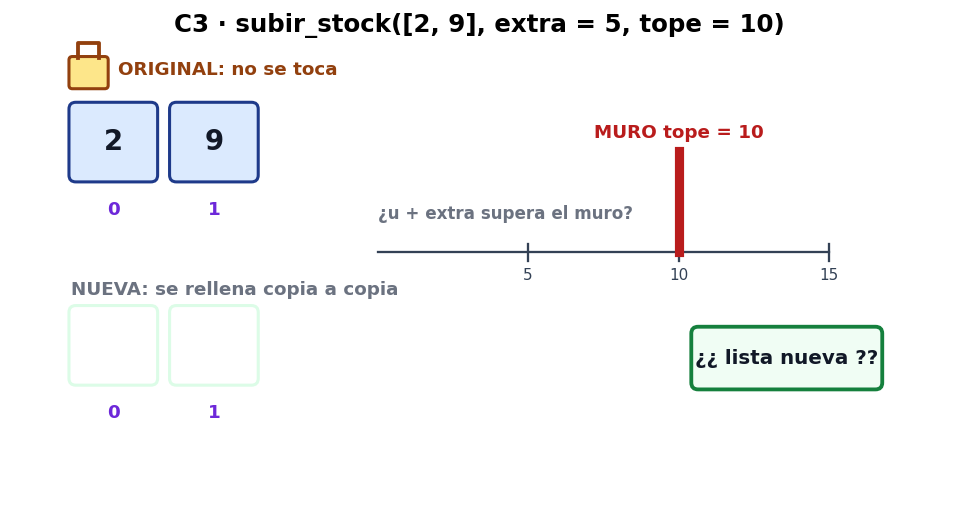

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c3_inicial.png")))

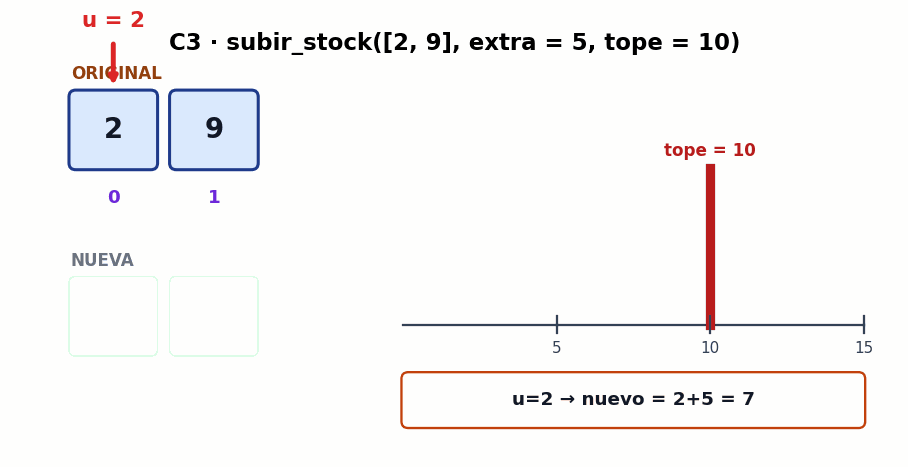

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "gifs/c3_subir_stock.gif"), format="gif"))

### 2 · Preguntas y errores a provocar

| Pregunta | Respuesta esperada |
|---|---|
| ¿Por qué lista nueva? | El enunciado lo exige; y el taller perdería el registro |
| ¿extra = 0 sobre algo ya alto? | `[12],0,10` → `[10]`: el muro sigue ahí |
| ¿extra negativo? | Permitido: `[5],-3,10` → `[2]` (baja stock) |

| Error a dibujar | Contraejemplo que lo delata |
|---|---|
| `nueva = unidades` (alias) | modifica la original: ¡misma cinta, dos nombres! |
| mutar `unidades[i]` | tachar una caja de la cinta de arriba (X roja) |
| `return` dentro del for | devuelve `[7]`, no `[7, 10]` |
| sin muro | `[2,9]+5` → `[7,14]` y 14 > tope |

In [ ]:
# ❌ ERROR 1: alias — `nueva = unidades` es LA MISMA lista
def mal_alias(unidades, extra, tope):
    nueva = unidades          # dos nombres, UNA cinta
    for i in range(len(nueva)):
        nuevo = nueva[i] + extra
        if nuevo > tope:
            nuevo = tope
        nueva[i] = nuevo
    return nueva

u = [2, 9]
salida = mal_alias(u, 5, 10)
print("devuelve:", salida, " pero la original quedó:", u, "¡MUTADA!")


# ❌ ERROR 2: return dentro del for (solo transforma el primero)
def mal_return(unidades, extra, tope):
    nueva = []
    for u in unidades:
        nuevo = u + extra
        if nuevo > tope:
            nuevo = tope
        nueva.append(nuevo)
        return nueva

print("mal_return ->", mal_return([2, 9], 5, 10), " (debe ser [7, 10])")

devuelve: [7, 10]  pero la original quedó: [7, 10] ¡MUTADA!
mal_return -> [7]  (debe ser [7, 10])


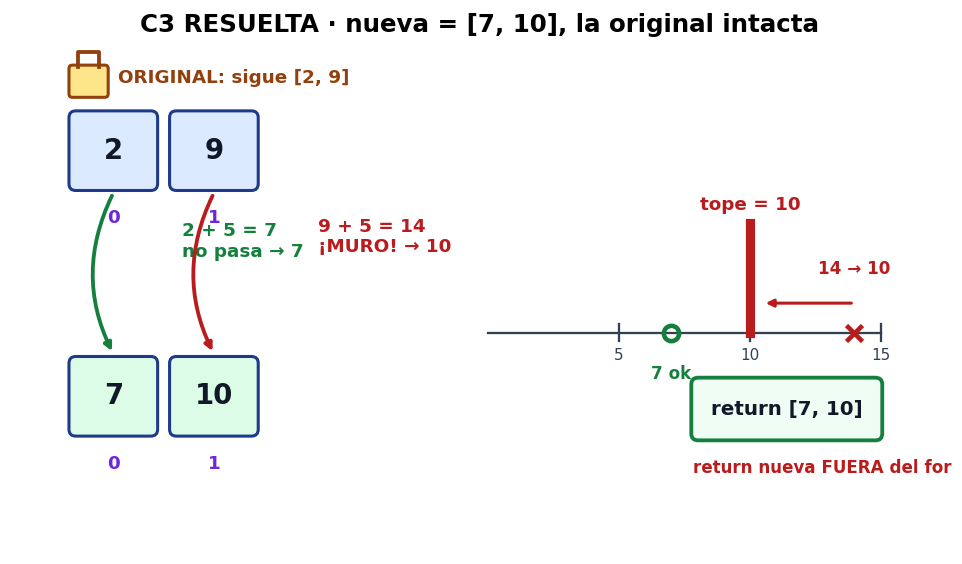

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c3_resuelta.png")))

### 3 · Del dibujo al código

La receta se traduce en el bloque de código siguiente, con una instrucción por línea y sangría visible.

In [ ]:
# ✅ SOLUCIÓN
def subir_stock(unidades, extra, tope):
    # lista NUEVA: la original no se toca
    nueva = []
    for u in unidades:
        nuevo = u + extra
        if nuevo > tope:
            nuevo = tope
        nueva.append(nuevo)
    return nueva

print(subir_stock([2, 9], 5, 10))   # [7, 10]
print(subir_stock([4], 0, 10))      # [4]
print(subir_stock([], 3, 10))       # []

[7, 10]
[4]
[]


### 4 · Casos límite (incluye la prueba de NO mutación)

In [ ]:
pruebas = [([2, 9], 5, 10, [7, 10]), ([4], 0, 10, [4]),
           ([], 3, 10, []), ([12], 0, 10, [10]),   # extra 0: el muro capa
           ([5], -3, 10, [2]),                     # extra negativo: permitido
           ([20], 5, 10, [10]), ([5], 5, 10, [10])]  # tope exacto / superado
for unds, ex, tp, esperado in pruebas:
    obtenido = subir_stock(unds, ex, tp)
    assert obtenido == esperado, (unds, ex, tp, obtenido, esperado)

# la prueba definitiva: la original NO cambia
original = [2, 9]
resultado = subir_stock(original, 5, 10)
assert original == [2, 9], "¡la lista original ha mutado!"
print("todas las pruebas de C3 OK — y la original sigue:", original)

todas las pruebas de C3 OK — y la original sigue: [2, 9]


**PythonTutor:**
[abrir subir_stock en PythonTutor](https://pythontutor.com/render.html#code=def%20subir_stock%28unidades%2C%20extra%2C%20tope%29%3A%0A%20%20%20%20%23%20lista%20NUEVA%3A%20la%20original%20no%20se%20toca%0A%20%20%20%20nueva%20%3D%20%5B%5D%0A%20%20%20%20for%20u%20in%20unidades%3A%0A%20%20%20%20%20%20%20%20nuevo%20%3D%20u%20%2B%20extra%0A%20%20%20%20%20%20%20%20if%20nuevo%20%3E%20tope%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20nuevo%20%3D%20tope%0A%20%20%20%20%20%20%20%20nueva.append%28nuevo%29%0A%20%20%20%20return%20nueva%0A%0Aprint%28subir_stock%28%5B2%2C%209%5D%2C%205%2C%2010%29%29&cumulative=false&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=3&rawInputLstJSON=%5B%5D&textReferences=false)

### Mini-reto C3

`bajar_stock(unidades, menos, suelo)` → lista nueva con cada cantidad
**menos** `menos`, sin quedar por debajo de `suelo`; la original intacta.
Es C3 con el muro abajo.

**Solución del reto C3** *(solo profesor)*:

In [ ]:
def bajar_stock(unidades, menos, suelo):
    nueva = []
    for u in unidades:
        nuevo = u - menos
        if nuevo < suelo:
            nuevo = suelo
        nueva.append(nuevo)
    return nueva

assert bajar_stock([9, 2], 5, 3) == [4, 3]
assert bajar_stock([], 5, 3) == []
assert bajar_stock([10], -2, 3) == [12]   # menos negativo también sube
print("reto C3 OK")

reto C3 OK


## Cierre (10 min)

**Tabla resumen colectiva** - la clase dicta, el profesor escribe:

| | ¿Qué recorro? | ¿Qué pregunto? | ¿Qué hago? |
|---|---|---|---|
| C1 | mediciones + `pos` | `m > limite` | PARAR → `return pos`; si cae el dedo → `-1` |
| C2 | caracteres | al espacio: `0 < longitud < maximo` | CONTAR +1 y reiniciar; chequeo final fuera |
| C3 | unidades | `u + extra > tope` | GUARDAR capado en `nueva`; `return` fuera |

**Quiz de casos límite** (predicen antes de revelar):

1. `primera_revision([], 10)` → **-1**
2. `primera_revision([11], 10)` → **0**
3. `primera_revision([10], 10)` → **-1** (estricto)
4. `contar_cortas("   ", 5)` → **0**
5. `contar_cortas("hoy", 5)` → **1** (la última palabra se comprueba al salir)
6. `contar_cortas("sieteaa", 7)` → **0** (estricto)
7. `subir_stock([12], 0, 10)` → **[10]** (el muro capa aunque extra=0)
8. `subir_stock([5], -3, 10)` → **[2]** (extra negativo permitido)
9. Tras `subir_stock(u, 5, 10)`, `u` vale → **lo mismo que antes**

**Los 4 principios de la sesión:**

1. **La máquina antes que el dato** - cinta-pregunta-cubo abstracta y
   actuada; el ejemplo solo sirve para verla funcionar.
2. **Una sola plantilla, tres ejercicios** - la tabla de 3 columnas es el
   esqueleto; programar es responder tres preguntas.
3. **El código es traducción** - solo se escribe cuando la receta en
   español existe; cada línea se lee del dibujo.
4. **Provocar el error, no anunciarlo** - se programa mal primero y el
   contraejemplo lo delata; la corrección deja marca física en la pizarra.

## Regenerar las figuras

Todas las figuras se generan con `figuras.py` (matplotlib + Pillow, sin
servicios externos). Para regenerarlas desde este cuaderno, ejecútalo con
el directorio del paquete como base:

In [ ]:
# Regenera las figuras sin archivos externos.
FUENTE_FIGURAS = '"""Figuras de pizarra para la Parte C — taller de bicis de Marina.\n\nGenera, sin servicios externos (solo matplotlib + Pillow):\n  - PNGs de pizarra (maquina + inicial/resuelta por ejercicio) en ./figuras\n  - fotogramas PNG por GIF en ./gifs/fotogramas/{c1,c2,c3}\n  - GIFs animados en ./gifs\n\nUso:\n    python3 figuras.py            # regenera todo\n    import figuras; figuras.regenerar_todo()\n"""\nimport io\nfrom pathlib import Path\n\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nfrom matplotlib.patches import FancyBboxPatch\nfrom PIL import Image\n\nBASE = Path(__file__).resolve().parent\nDIR_FIG = BASE / "figuras"\nDIR_GIF = BASE / "gifs"\nDIR_FOT = DIR_GIF / "fotogramas"\n\nCOL = {\n    "caja": "#dbeafe", "borde": "#1e3a8a", "idx": "#6d28d9",\n    "si": "#15803d", "no": "#b91c1c", "dedo": "#dc2626",\n    "out": "#15803d", "muro": "#b91c1c", "nueva": "#dcfce7",\n    "gris": "#6b7280", "warn": "#b45309", "vacio": "#f3f4f6",\n}\n\n# ---------------------------------------------------------------- utilidades\n\ndef _ax(w, h, xlim, ylim):\n    fig, ax = plt.subplots(figsize=(w, h), dpi=110)\n    ax.set_xlim(*xlim)\n    ax.set_ylim(*ylim)\n    ax.axis("off")\n    return fig, ax\n\n\ndef caja(ax, x, y, w, h, texto="", fc=None, ec=None, fs=18, tc="#111827", lw=2):\n    fc = fc or COL["caja"]\n    ec = ec or COL["borde"]\n    ax.add_patch(FancyBboxPatch(\n        (x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",\n        fc=fc, ec=ec, lw=lw))\n    if texto != "":\n        ax.text(x + w / 2, y + h / 2, texto, ha="center", va="center",\n                fontsize=fs, color=tc, fontweight="bold")\n\n\ndef cinta(ax, valores, x0, y, bw=1.0, bh=0.9, gap=0.18, fc=None,\n          idx=True, fs=18, prefijo=""):\n    """Dibuja las cajas de la cinta; devuelve los centros x de cada caja."""\n    fc = fc or COL["caja"]\n    centros = []\n    for i, v in enumerate(valores):\n        x = x0 + i * (bw + gap)\n        caja(ax, x, y, bw, bh, str(v), fc=fc, fs=fs)\n        if idx:\n            ax.text(x + bw / 2, y - 0.24, prefijo + str(i), ha="center",\n                    va="top", fontsize=12, color=COL["idx"], fontweight="bold")\n        centros.append(x + bw / 2)\n    return centros\n\n\ndef dedo(ax, x, y, texto="pos", color=None):\n    color = color or COL["dedo"]\n    ax.annotate("", xy=(x, y + 0.04), xytext=(x, y + 0.6),\n                arrowprops=dict(arrowstyle="-|>", lw=3.2, color=color))\n    ax.text(x, y + 0.72, texto, ha="center", va="bottom", fontsize=14,\n            color=color, fontweight="bold")\n\n\ndef veredicto(ax, x, y, ok):\n    ax.text(x, y, "SÍ" if ok else "NO", ha="center", va="center",\n            fontsize=14, fontweight="bold",\n            color=COL["si"] if ok else COL["no"])\n\n\ndef globo(ax, x, y, w, texto, fc="#fff7ed", ec="#c2410c", fs=12):\n    caja(ax, x, y, w, 0.62, texto, fc=fc, ec=ec, fs=fs, lw=1.5)\n\n\ndef salida(ax, x, y, texto, fs=15):\n    caja(ax, x, y, 2.2, 0.7, texto, fc="#f0fdf4", ec=COL["out"], fs=fs, lw=2.5)\n\n\ndef guardar(fig, nombre):\n    DIR_FIG.mkdir(parents=True, exist_ok=True)\n    fig.savefig(DIR_FIG / nombre, bbox_inches="tight", facecolor="white")\n    plt.close(fig)\n\n\ndef _a_png(fig):\n    buf = io.BytesIO()\n    fig.savefig(buf, format="png", bbox_inches="tight", facecolor="white")\n    plt.close(fig)\n    buf.seek(0)\n    return Image.open(buf).convert("P", palette=Image.ADAPTIVE)\n\n\ndef _gif(frames, carpeta, nombre, duracion=900):\n    """frames: lista de PIL images. Guarda fotogramas PNG y el GIF."""\n    d = DIR_FOT / carpeta\n    d.mkdir(parents=True, exist_ok=True)\n    for v in d.glob("*.png"):\n        v.unlink()\n    imgs = []\n    for i, f in enumerate(frames):\n        f.save(d / f"f{i:02d}.png")\n        imgs.append(f)\n    DIR_GIF.mkdir(parents=True, exist_ok=True)\n    imgs[0].save(DIR_GIF / nombre, save_all=True, append_images=imgs[1:],\n                 duration=duracion, loop=0)\n\n# ------------------------------------------------------------ pizarra maquina\n\ndef fig_maquina():\n    fig, ax = _ax(11, 5.4, (0, 11), (0, 5.4))\n    ax.text(5.5, 5.15, "RECORRER, COMPROBAR Y DECIDIR — C1, C2 y C3",\n            ha="center", fontsize=18, fontweight="bold")\n\n    xs = cinta(ax, ["d1", "d2", "d3", "d4"], 0.4, 3.3, idx=False, fs=15)\n    ax.text(0.4, 3.0, "1 · ¿QUÉ RECORRO?", fontsize=11,\n            color=COL["gris"], fontweight="bold")\n\n    caja(ax, 5.5, 3.15, 2.0, 1.2, "¿PREGUNTA?\\nSÍ / NO",\n         fc="#fef3c7", ec=COL["warn"], fs=14)\n    ax.text(5.5, 2.9, "2 · ¿QUÉ PREGUNTO?", fontsize=9,\n            color=COL["gris"], fontweight="bold")\n    ax.annotate("", xy=(5.45, 3.75), xytext=(4.62, 3.75),\n                arrowprops=dict(arrowstyle="-|>", lw=2.5, color="#374151"))\n\n    for y, t, fc, ec in [\n        (3.95, "PARAR → devolver ya", "#fee2e2", "#b91c1c"),\n        (2.95, "CONTAR +1", "#dcfce7", "#15803d"),\n        (1.95, "GUARDAR en lista nueva", "#e0e7ff", "#4338ca"),\n    ]:\n        caja(ax, 8.55, y, 2.25, 0.8, t, fc=fc, ec=ec, fs=9)\n    for y in (4.35, 3.35, 2.35):\n        ax.annotate("", xy=(8.5, y), xytext=(7.55, 3.75),\n                    arrowprops=dict(arrowstyle="-|>", lw=2, color="#374151"))\n    ax.text(7.7, 1.7, "3 · ¿QUÉ HAGO CON LA RESPUESTA?", fontsize=8,\n            color=COL["gris"], fontweight="bold")\n\n    ax.add_patch(FancyBboxPatch((0.4, 0.35), 10.2, 0.85,\n                 boxstyle="round,pad=0.02,rounding_size=0.06",\n                 fc="#f8fafc", ec="#94a3b8", lw=1.5))\n    ax.text(5.5, 0.78,\n            "PARAR = C1 (primera_revision)      CONTAR = C2 (contar_cortas)      GUARDAR = C3 (subir_stock)",\n            ha="center", fontsize=9, fontweight="bold", color="#334155")\n    guardar(fig, "pizarra_maquina.png")\n\n# ---------------------------------------------------------------- C1 pizarras\n\nDATOS_C1 = [3, 8, 12, 6, 10]\n\ndef fig_c1_inicial():\n    fig, ax = _ax(11, 5.0, (0, 11), (0, 5.0))\n    ax.text(5.5, 4.75, "C1 · primera_revision([3, 8, 12, 6, 10], limite = 10)",\n            ha="center", fontsize=16, fontweight="bold")\n\n    cinta(ax, DATOS_C1, 0.7, 3.0)\n    ax.text(0.7, 4.15, "¿QUÉ RECORRO? → la cinta de mediciones", fontsize=12,\n            color=COL["gris"], fontweight="bold")\n    globo(ax, 7.0, 3.1, 3.4, "¿PREGUNTA?   m > limite")\n    ax.text(7.0, 2.85, "¿posición o valor? ¡son dos carteles distintos!",\n            fontsize=11, color=COL["warn"], fontweight="bold")\n\n    salida(ax, 0.7, 1.5, "¿¿ qué devuelve ??", fs=13)\n    ax.text(0.7, 1.15, "¿Y SI NINGUNA SUPERA?   →   devolver -1",\n            fontsize=13, color=COL["no"], fontweight="bold")\n    guardar(fig, "c1_inicial.png")\n\n\ndef fig_c1_resuelta():\n    fig, ax = _ax(11, 7.4, (0, 11), (0, 7.4))\n    ax.text(5.5, 7.15, "C1 RESUELTA · para en el primer SÍ y devuelve pos",\n            ha="center", fontsize=16, fontweight="bold")\n\n    # --- cinta 1: se para en el indice 2\n    centros = cinta(ax, DATOS_C1, 0.7, 5.0)\n    for i, ok in [(0, False), (1, False), (2, True)]:\n        veredicto(ax, centros[i], 6.25, ok)\n    for i in (3, 4):\n        ax.text(centros[i], 6.25, "ya no miro", ha="center", va="center",\n                fontsize=10, color=COL["gris"], style="italic")\n    dedo(ax, centros[2], 5.9, "pos = 2")\n    ax.text(centros[2], 4.45, "STOP", ha="center", fontsize=14,\n            fontweight="bold", color=COL["no"])\n    salida(ax, 7.6, 5.1, "return 2")\n\n    ax.text(0.7, 3.9, "pos va 0 → 1 → 2 hasta el primer SÍ; "\n                      "return pos está DENTRO del if (solo al acertar)",\n            fontsize=11, color="#334155")\n\n    # --- cinta 2: ninguna supera -> dedo cae por el borde\n    c2 = cinta(ax, [3, 8], 0.7, 1.9)\n    for i in (0, 1):\n        veredicto(ax, c2[i], 3.15, False)\n    x_fin = c2[-1] + 0.9\n    ax.annotate("", xy=(x_fin, 1.55), xytext=(c2[-1] + 0.15, 2.6),\n                arrowprops=dict(arrowstyle="-|>", lw=3.2, color=COL["dedo"],\n                                connectionstyle="arc3,rad=0.35"))\n    ax.text(x_fin - 0.15, 2.75, "¡el dedo cae\\npor el borde!", ha="center",\n            fontsize=12, color=COL["dedo"], fontweight="bold")\n    salida(ax, 5.0, 1.85, "return -1")\n    ax.text(5.0, 1.5, "return -1 va FUERA del for (desindentado)",\n            fontsize=11, color=COL["no"], fontweight="bold")\n    guardar(fig, "c1_resuelta.png")\n\n# ---------------------------------------------------------------- C2 pizarras\n\nTEXTO_C2 = "  rueda pinchada hoy  "\n\ndef _cinta_chars(ax, texto, x0, y, bw=0.52, gap=0.06, fs=15):\n    centros = []\n    for i, c in enumerate(texto):\n        x = x0 + i * (bw + gap)\n        visible = c if c != " " else "␣"\n        fc = COL["caja"] if c != " " else COL["vacio"]\n        caja(ax, x, y, bw, 0.7, visible, fc=fc, fs=fs, lw=1.5)\n        centros.append(x + bw / 2)\n    return centros\n\n\ndef fig_c2_inicial():\n    fig, ax = _ax(13, 5.0, (0, 13.2), (0, 5.0))\n    ax.text(6.6, 4.75, \'C2 · contar_cortas("  rueda pinchada hoy  ", maximo = 7)\',\n            ha="center", fontsize=15, fontweight="bold")\n\n    _cinta_chars(ax, TEXTO_C2, 0.35, 3.2)\n    ax.text(0.35, 4.15, "¿QUÉ RECORRO? → carácter a carácter (␣ = espacio)",\n            fontsize=11, color=COL["gris"], fontweight="bold")\n\n    caja(ax, 0.9, 1.7, 2.6, 0.8, "longitud = 0", fc="#fef3c7",\n         ec=COL["warn"], fs=14)\n    caja(ax, 4.4, 1.7, 2.6, 0.8, "contador = 0", fc="#dcfce7",\n         ec=COL["si"], fs=14)\n    globo(ax, 7.9, 1.78, 4.2, "al espacio: ¿0 < longitud < 7?", fs=10)\n\n    ax.text(0.9, 1.1, "¿Y LA ÚLTIMA PALABRA? no acaba en espacio → "\n                      "comprobar AL SALIR del for", fontsize=12,\n            color=COL["no"], fontweight="bold")\n    guardar(fig, "c2_inicial.png")\n\n\ndef fig_c2_resuelta():\n    fig, ax = _ax(13, 6.2, (0, 13.2), (0, 6.2))\n    ax.text(6.6, 5.95, \'C2 RESUELTA · "  rueda pinchada hoy  " → 2 palabras cortas\',\n            ha="center", fontsize=15, fontweight="bold")\n\n    centros = _cinta_chars(ax, TEXTO_C2, 0.35, 4.0)\n    # longitud bajo cada carácter\n    longitud = 0\n    espacios = []\n    for i, c in enumerate(TEXTO_C2):\n        if c == " ":\n            ax.text(centros[i], 3.72, "0", ha="center", fontsize=10,\n                    color=COL["gris"])\n            espacios.append(i)\n            longitud = 0\n        else:\n            longitud += 1\n            ax.text(centros[i], 3.72, str(longitud), ha="center",\n                    fontsize=10, color=COL["warn"], fontweight="bold")\n\n    # veredictos en cada espacio + al final\n    ax.text(centros[2], 5.0, "␣: 0 no cuenta", ha="center", fontsize=9,\n            color=COL["gris"])\n    ax.text(centros[7], 5.0, "␣: 5 <7 → +1", ha="center", fontsize=10,\n            color=COL["si"], fontweight="bold")\n    ax.text(centros[16], 5.0, "␣: 8 ✗", ha="center", fontsize=10,\n            color=COL["no"], fontweight="bold")\n    ax.text(centros[20] - 0.5, 5.0, "␣: 3 <7 → +1", ha="center", fontsize=10,\n            color=COL["si"], fontweight="bold")\n    ax.text(centros[-1] - 0.35, 5.0, "fin", ha="center", fontsize=9,\n            color=COL["gris"])\n\n    caja(ax, 1.4, 2.2, 2.8, 0.8, "longitud = variable", fc="#fef3c7",\n         ec=COL["warn"], fs=12)\n    caja(ax, 5.0, 2.2, 2.8, 0.8, "contador = 2", fc="#dcfce7",\n         ec=COL["si"], fs=14)\n    salida(ax, 9.0, 2.25, "return 2", fs=14)\n\n    ax.text(1.4, 1.5,\n            "los espacios repetidos y de los extremos dejan longitud = 0 → "\n            "no cuentan nunca",\n            fontsize=11, color="#334155")\n    ax.text(1.4, 1.05,\n            "«hoy» acaba en espacio… pero si no acabara, el if FINAL "\n            "(fuera del for) la comprueba igual",\n            fontsize=11, color=COL["no"])\n    guardar(fig, "c2_resuelta.png")\n\n# ---------------------------------------------------------------- C3 pizarras\n\ndef _padlock(ax, x, y):\n    ax.add_patch(FancyBboxPatch((x, y), 0.42, 0.34,\n                 boxstyle="round,pad=0.02,rounding_size=0.04",\n                 fc="#fde68a", ec="#92400e", lw=2))\n    ax.plot([x + 0.09, x + 0.09, x + 0.33, x + 0.33],\n            [y + 0.34, y + 0.52, y + 0.52, y + 0.34],\n            color="#92400e", lw=2.5)\n\n\ndef fig_c3_inicial():\n    fig, ax = _ax(11, 6.0, (0, 11), (0, 6.0))\n    ax.text(5.5, 5.75, "C3 · subir_stock([2, 9], extra = 5, tope = 10)",\n            ha="center", fontsize=16, fontweight="bold")\n\n    cinta(ax, [2, 9], 0.7, 4.0)\n    _padlock(ax, 0.7, 5.1)\n    ax.text(1.25, 5.25, "ORIGINAL: no se toca", fontsize=12,\n            color="#92400e", fontweight="bold")\n\n    # cinta nueva vacía\n    for i in range(2):\n        caja(ax, 0.7 + i * 1.18, 1.6, 1.0, 0.9, "", fc="white",\n             ec=COL["nueva"], fs=14)\n        ax.text(1.2 + i * 1.18, 1.36, str(i), ha="center", va="top",\n                fontsize=12, color=COL["idx"], fontweight="bold")\n    ax.text(0.7, 2.65, "NUEVA: se rellena copia a copia", fontsize=12,\n            color=COL["gris"], fontweight="bold")\n\n    # muro del tope en una recta numérica\n    ax.plot([4.3, 9.6], [3.15, 3.15], color="#334155", lw=1.5)\n    for v in (5, 10, 15):\n        x = 4.3 + v / 15 * 5.3\n        ax.plot([x, x], [3.05, 3.25], color="#334155", lw=1.5)\n        ax.text(x, 2.82, str(v), ha="center", fontsize=10, color="#334155")\n    x_tope = 4.3 + 10 / 15 * 5.3\n    ax.plot([x_tope, x_tope], [3.15, 4.35], color=COL["muro"], lw=6)\n    ax.text(x_tope, 4.5, "MURO tope = 10", ha="center", fontsize=12,\n            color=COL["muro"], fontweight="bold")\n    ax.text(4.3, 3.55, "¿u + extra supera el muro?", fontsize=11,\n            color=COL["gris"], fontweight="bold")\n    salida(ax, 8.0, 1.55, "¿¿ lista nueva ??", fs=13)\n    guardar(fig, "c3_inicial.png")\n\n\ndef fig_c3_resuelta():\n    fig, ax = _ax(11, 6.4, (0, 11), (0, 6.4))\n    ax.text(5.5, 6.15, "C3 RESUELTA · nueva = [7, 10], la original intacta",\n            ha="center", fontsize=16, fontweight="bold")\n\n    centros = cinta(ax, [2, 9], 0.7, 4.3)\n    _padlock(ax, 0.7, 5.4)\n    ax.text(1.25, 5.55, "ORIGINAL: sigue [2, 9]", fontsize=12,\n            color="#92400e", fontweight="bold")\n\n    for i, v in enumerate([7, 10]):\n        caja(ax, 0.7 + i * 1.18, 1.4, 1.0, 0.9, str(v), fc=COL["nueva"], fs=18)\n        ax.text(1.2 + i * 1.18, 1.16, str(i), ha="center", va="top",\n                fontsize=12, color=COL["idx"], fontweight="bold")\n\n    ax.annotate("", xy=(1.2, 2.35), xytext=(centros[0], 4.25),\n                arrowprops=dict(arrowstyle="-|>", lw=2.5, color=COL["out"],\n                                connectionstyle="arc3,rad=0.25"))\n    ax.text(2.0, 3.5, "2 + 5 = 7\\nno pasa → 7", fontsize=12,\n            color=COL["out"], fontweight="bold")\n    ax.annotate("", xy=(2.38, 2.35), xytext=(centros[1], 4.25),\n                arrowprops=dict(arrowstyle="-|>", lw=2.5, color=COL["muro"],\n                                connectionstyle="arc3,rad=0.25"))\n    ax.text(3.6, 3.55, "9 + 5 = 14\\n¡MURO! → 10", fontsize=12,\n            color=COL["muro"], fontweight="bold")\n\n    # recta con muro\n    ax.plot([5.6, 10.2], [2.6, 2.6], color="#334155", lw=1.5)\n    for v in (5, 10, 15):\n        x = 5.6 + v / 15 * 4.6\n        ax.plot([x, x], [2.5, 2.7], color="#334155", lw=1.5)\n        ax.text(x, 2.28, str(v), ha="center", fontsize=10, color="#334155")\n    x_tope = 5.6 + 10 / 15 * 4.6\n    ax.plot([x_tope, x_tope], [2.6, 3.9], color=COL["muro"], lw=6)\n    ax.text(x_tope, 4.05, "tope = 10", ha="center", fontsize=12,\n            color=COL["muro"], fontweight="bold")\n    ax.plot(5.6 + 7 / 15 * 4.6, 2.6, "o", ms=10, color=COL["out"],\n            mfc="none", mew=3)\n    ax.text(5.6 + 7 / 15 * 4.6, 2.05, "7 ok", ha="center", fontsize=11,\n            color=COL["out"], fontweight="bold")\n    ax.plot(5.6 + 14 / 15 * 4.6, 2.6, "x", ms=11, color=COL["muro"], mew=3)\n    ax.annotate("", xy=(x_tope + 0.15, 2.95), xytext=(5.6 + 14 / 15 * 4.6, 2.95),\n                arrowprops=dict(arrowstyle="-|>", lw=2, color=COL["muro"]))\n    ax.text(5.6 + 14 / 15 * 4.6, 3.3, "14 → 10", ha="center", fontsize=11,\n            color=COL["muro"], fontweight="bold")\n\n    salida(ax, 8.0, 1.35, "return [7, 10]", fs=13)\n    ax.text(8.0, 0.95, "return nueva FUERA del for", fontsize=11,\n            color=COL["no"], fontweight="bold")\n    guardar(fig, "c3_resuelta.png")\n\n# ------------------------------------------------------------------ GIF C1\n\ndef _frame_c1(paso):\n    """paso: 0..10 (ver _gif_c1)."""\n    fig, ax = _ax(10.4, 4.4, (0, 10.4), (0, 4.4))\n    datos, limite = DATOS_C1, 10\n    ax.text(5.2, 4.15, "C1 · primera_revision(mediciones, 10)",\n            ha="center", fontsize=15, fontweight="bold")\n    caja(ax, 0.35, 0.45, 1.7, 0.7, f"pos = {min(paso // 2, 2)}",\n         fc="#fef3c7", ec=COL["warn"], fs=13)\n    fases = [(0, "¿3 > 10?"), (1, "NO → pos=1"), (2, "¿8 > 10?"),\n             (3, "NO → pos=2"), (4, "¿12 > 10?"), (5, "¡SÍ!"),\n             (6, "return pos → 2"), (7, "otra cinta: [3, 8]"),\n             (8, "NO, NO…"), (9, "¡cae por el borde!"),\n             (10, "return -1")]\n    globo(ax, 2.3, 0.45, 4.3, fases[paso][1], fs=13)\n\n    if paso <= 6:\n        centros = cinta(ax, datos, 0.7, 2.1)\n        marcados = {0: False, 1: False, 2: True}\n        for i in range(3):\n            if paso // 2 > i or (paso // 2 == i and paso >= 5):\n                veredicto(ax, centros[i], 3.35, marcados[i])\n        if paso == 6:\n            salida(ax, 7.6, 2.2, "return 2", fs=14)\n            dedo(ax, centros[2], 3.0, "pos = 2")\n        else:\n            i = min(paso // 2, 2)\n            dedo(ax, centros[i], 3.0, "pos")\n    else:\n        centros = cinta(ax, [3, 8], 0.7, 2.1)\n        if paso >= 8:\n            veredicto(ax, centros[0], 3.35, False)\n            veredicto(ax, centros[1], 3.35, False)\n        if paso == 8:\n            dedo(ax, centros[1], 3.0, "pos = 2")\n        if paso >= 9:\n            xf = centros[-1] + 0.9\n            ax.annotate("", xy=(xf, 1.75), xytext=(centros[-1] + 0.15, 2.85),\n                        arrowprops=dict(arrowstyle="-|>", lw=3,\n                                        color=COL["dedo"],\n                                        connectionstyle="arc3,rad=0.35"))\n            ax.text(xf - 0.1, 3.05, "¡cae!", ha="center", fontsize=12,\n                    color=COL["dedo"], fontweight="bold")\n        if paso == 10:\n            salida(ax, 5.2, 2.15, "return -1", fs=14)\n    return _a_png(fig)\n\n\ndef _gif_c1():\n    frames = [_frame_c1(p) for p in range(11)]\n    frames.append(frames[-1])  # retiene el final\n    _gif(frames, "c1", "c1_primera_revision.gif", duracion=950)\n\n# ------------------------------------------------------------------ GIF C2\n\nTEXTO_GIF_C2 = "rueda pinchada hoy"\n\ndef _frame_c2(paso):\n    fig, ax = _ax(11.6, 4.0, (0, 11.6), (0, 4.0))\n    texto, maximo = TEXTO_GIF_C2, 7\n    ax.text(5.8, 3.8, f\'C2 · contar_cortas("{texto}", {maximo})\',\n            ha="center", fontsize=14, fontweight="bold")\n    centros = _cinta_chars(ax, texto, 0.5, 1.9, bw=0.55)\n\n    # recalcular estado en el carácter `paso`\n    longitud, contador = 0, 0\n    evento = ""\n    for i in range(min(paso, len(texto))):\n        c = texto[i]\n        if c == " ":\n            evento = f"␣ ¿0<{longitud}<{maximo}? "\n            if 0 < longitud < maximo:\n                contador += 1\n                evento += "SÍ +1"\n            else:\n                evento += "NO"\n            longitud = 0\n        else:\n            longitud += 1\n            evento = f"+1 letra → longitud {longitud}"\n    if paso >= len(texto):\n        evento = f"FIN: última palabra ¿0<{longitud}<{maximo}? "\n        if 0 < longitud < maximo:\n            contador += 1\n            evento += "SÍ +1"\n        else:\n            evento += "NO"\n\n    # longitud bajo cada carácter ya visto\n    longitud = 0\n    for i in range(min(paso, len(texto))):\n        if texto[i] == " ":\n            longitud = 0\n            ax.text(centros[i], 1.62, "0", ha="center", fontsize=9,\n                    color=COL["gris"])\n        else:\n            longitud += 1\n            ax.text(centros[i], 1.62, str(longitud), ha="center",\n                    fontsize=9, color=COL["warn"], fontweight="bold")\n\n    if paso < len(texto):\n        dedo(ax, centros[paso], 2.62, "leo")\n    else:\n        dedo(ax, centros[-1] + 0.7, 2.62, "salgo")\n\n    caja(ax, 0.5, 0.45, 2.5, 0.7, f"longitud = {longitud}",\n         fc="#fef3c7", ec=COL["warn"], fs=13)\n    caja(ax, 3.3, 0.45, 2.5, 0.7, f"contador = {contador}",\n         fc="#dcfce7", ec=COL["si"], fs=13)\n    globo(ax, 6.3, 0.45, 5.0, evento, fs=12)\n    if paso >= len(texto):\n        salida(ax, 9.4, 2.6, f"return {contador}", fs=13)\n    return _a_png(fig)\n\n\ndef _gif_c2():\n    n = len(TEXTO_GIF_C2)\n    frames = [_frame_c2(p) for p in range(n + 1)]\n    frames.append(frames[-1])\n    _gif(frames, "c2", "c2_contar_cortas.gif", duracion=750)\n\n# ------------------------------------------------------------------ GIF C3\n\ndef _frame_c3(paso):\n    fig, ax = _ax(10.4, 5.0, (0, 10.4), (0, 5.0))\n    unidades, extra, tope = [2, 9], 5, 10\n    ax.text(5.2, 4.8, "C3 · subir_stock([2, 9], extra = 5, tope = 10)",\n            ha="center", fontsize=15, fontweight="bold")\n\n    centros = cinta(ax, unidades, 0.7, 3.4)\n    ax.text(0.7, 4.45, "ORIGINAL", fontsize=11, color="#92400e",\n            fontweight="bold")\n\n    nueva = []\n    pasos_txt = ["u=2 → nuevo = 2+5 = 7", "7 ≤ 10 → append → nueva=[7]",\n                 "u=9 → nuevo = 9+5 = 14", "14 > 10 ¡MURO! → nuevo = 10",\n                 "append → nueva=[7, 10]", "return nueva → [7, 10]  "\n                 "(original intacta)"]\n    if paso >= 2:\n        nueva.append(7)\n    if paso >= 4:\n        nueva.append(10)\n\n    for i, v in enumerate(nueva):\n        caja(ax, 0.7 + i * 1.18, 1.2, 1.0, 0.9, str(v), fc=COL["nueva"])\n        ax.text(1.2 + i * 1.18, 0.96, str(i), ha="center", va="top",\n                fontsize=12, color=COL["idx"], fontweight="bold")\n    if not nueva:\n        for i in range(2):\n            caja(ax, 0.7 + i * 1.18, 1.2, 1.0, 0.9, "", fc="white",\n                 ec=COL["nueva"], lw=1.5)\n    ax.text(0.7, 2.25, "NUEVA", fontsize=11, color=COL["gris"],\n            fontweight="bold")\n\n    if paso == 0:\n        dedo(ax, centros[0], 4.3, "u = 2")\n    elif 2 <= paso <= 4:\n        dedo(ax, centros[1], 4.3, "u = 9")\n\n    # muro\n    ax.plot([4.6, 10.0], [1.55, 1.55], color="#334155", lw=1.5)\n    x_tope = 4.6 + 10 / 15 * 5.4\n    ax.plot([x_tope, x_tope], [1.55, 3.4], color=COL["muro"], lw=6)\n    ax.text(x_tope, 3.55, "tope = 10", ha="center", fontsize=11,\n            color=COL["muro"], fontweight="bold")\n    for v in (5, 10, 15):\n        x = 4.6 + v / 15 * 5.4\n        ax.plot([x, x], [1.45, 1.65], color="#334155", lw=1.5)\n        ax.text(x, 1.22, str(v), ha="center", fontsize=10, color="#334155")\n    if 1 <= paso <= 2:\n        ax.plot(4.6 + 7 / 15 * 5.4, 1.55, "o", ms=10, color=COL["out"],\n                mfc="none", mew=3)\n    if paso >= 3:\n        ax.plot(4.6 + 14 / 15 * 5.4, 1.55, "x", ms=11, color=COL["muro"],\n                mew=3)\n        ax.annotate("", xy=(x_tope + 0.12, 1.9),\n                    xytext=(4.6 + 14 / 15 * 5.4, 1.9),\n                    arrowprops=dict(arrowstyle="-|>", lw=2, color=COL["muro"]))\n\n    globo(ax, 4.6, 0.35, 5.4, pasos_txt[paso], fs=12)\n    return _a_png(fig)\n\n\ndef _gif_c3():\n    frames = [_frame_c3(p) for p in range(6)]\n    frames.append(frames[-1])\n    _gif(frames, "c3", "c3_subir_stock.gif", duracion=1100)\n\n# ------------------------------------------------------------------- orquesta\n\ndef regenerar_todo():\n    DIR_FIG.mkdir(parents=True, exist_ok=True)\n    fig_maquina()\n    fig_c1_inicial(); fig_c1_resuelta()\n    fig_c2_inicial(); fig_c2_resuelta()\n    fig_c3_inicial(); fig_c3_resuelta()\n    _gif_c1(); _gif_c2(); _gif_c3()\n    print("Figuras, fotogramas y GIFs regenerados en", BASE)\n\n\nif __name__ == "__main__":\n    regenerar_todo()\n'
(RAIZ / "figuras.py").write_text(FUENTE_FIGURAS, encoding="utf-8")
import runpy
runpy.run_path(str(RAIZ / "figuras.py"), run_name="__main__")

Figuras, fotogramas y GIFs regenerados en /tmp/parte_c_pizarra


{'__name__': '__main__',
 '__doc__': 'Figuras de pizarra para la Parte C — taller de bicis de Marina.\n\nGenera, sin servicios externos (solo matplotlib + Pillow):\n  - PNGs de pizarra (maquina + inicial/resuelta por ejercicio) en ./figuras\n  - fotogramas PNG por GIF en ./gifs/fotogramas/{c1,c2,c3}\n  - GIFs animados en ./gifs\n\nUso:\n    python3 figuras.py            # regenera todo\n    import figuras; figuras.regenerar_todo()\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/tmp/parte_c_pizarra/figuras.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, exceptions, and other objects.\n\nNoteworthy: None is the `nil' object; Ellipsis represents `...' in slices.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__impor

## Contenido del paquete

```
parte-C-pizarra-devin-web-SWE2/
├── cuaderno/parte-C-pizarra-devin-web-SWE2.ipynb   ← este cuaderno
├── figuras/            PNGs de pizarra (máquina + inicial/resuelta ×3)
├── excalidraw/         pizarras editables (.excalidraw)
├── gifs/               animaciones + fotogramas PNG por ejercicio
├── guion/              guion TXT para consultar en el móvil
├── chuleta/            chuleta de referencia rápida (md/html)
├── revision/           documento de revisión (html/pdf)
├── codigo/             soluciones.py + errores.py
├── figuras.py          regenera PNGs, fotogramas y GIFs
├── excalidraw_gen.py   regenera los .excalidraw
├── cuaderno_gen.py     regenera este cuaderno
└── generar_paquete.py  regenera el paquete completo
```

In [ ]:
#@title Descargar recursos docentes (Excalidraw, GIF, guion y PDF)
import base64
from pathlib import Path
paquete = Path("/tmp/recursos-parte-C.zip")
paquete.write_bytes(base64.b64decode('...'))
try:
    from google.colab import files
    files.download(str(paquete))
except ImportError:
    print("Recursos guardados en", paquete)
